In [8]:
# Mount Google Drive and Set Paths
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [11]:
# Setup and load data

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set(style="whitegrid")

base_dir = Path("/content/drive/MyDrive/gdsc-drug-response")
data_path = base_dir / "processed" / "fulvestrant_rnaseq_modelready.csv"

df = pd.read_csv(data_path)
df.shape
df.head()

,model_id,drug_name,ln_ic50,A1BG,A1BG-AS1,A1CF,A2M,A2M-AS1,A2ML1,A2ML1-AS1,...,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11AP1,ZYG11B,ZYX,ZYXP1,ZZEF1,ZZZ3
0,SIDM01132,Fulvestrant,2.325255,5.18545,2.9833,0.0000,0.52325,0.0000,0.0213,0.0000,...,0.31285,1.60475,3.10825,0.6801,0.0,2.58955,5.95435,0.0,3.47415,4.0301
1,SIDM00848,Fulvestrant,2.710606,4.86890,3.4476,0.0000,1.99640,0.1243,3.1890,0.0000,...,1.68260,2.33060,5.18630,0.0841,0.0,3.09930,5.52420,NaN,3.60640,4.5211
2,SIDM00263,Fulvestrant,2.869553,5.03650,3.5558,0.0144,3.98550,0.2987,5.7968,0.0566,...,2.94860,3.39230,6.59630,4.1787,0.0,4.68090,6.37780,0.0,4.57590,5.6946
3,SIDM00269,Fulvestrant,2.028349,4.54970,3.8001,0.0841,3.21570,0.0566,0.5753,0.0000,...,2.82980,3.41280,6.78270,2.3190,0.0,4.21410,9.01050,0.0,4.93400,5.4561
4,SIDM00203,Fulvestrant,3.070346,4.22500,3.2095,0.0144,0.50590,0.0976,2.8156,0.0000,...,2.49570,3.47640,5.30710,3.0321,0.0,4.47310,6.95290,0.0,4.35900,5.3366


In [12]:
# Define key columns:

model_col    = "model_id"
drug_col     = "drug_name"
response_col = "ln_ic50"

non_feature_cols = [model_col, drug_col, response_col]
feature_cols = [c for c in df.columns if c not in non_feature_cols]

len(feature_cols)

41143

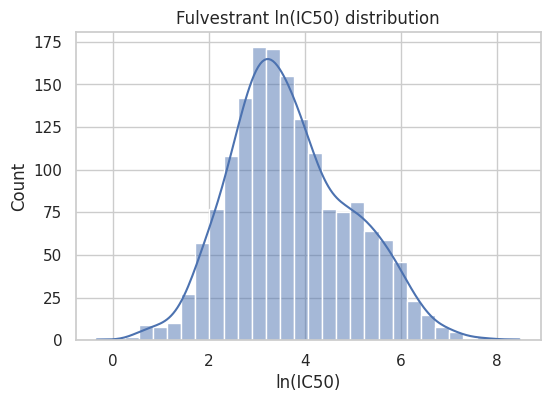

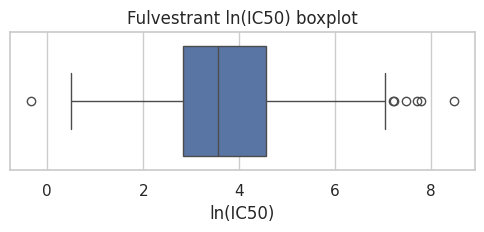

In [13]:
# Basic checks and summary of LN_IC50

df[[model_col, drug_col, response_col]].head()
df[response_col].describe()

plt.figure(figsize=(6,4))
sns.histplot(df[response_col], bins=30, kde=True)
plt.xlabel("ln(IC50)")
plt.title("Fulvestrant ln(IC50) distribution")
plt.show()

plt.figure(figsize=(6,1.8))
sns.boxplot(x=df[response_col])
plt.xlabel("ln(IC50)")
plt.title("Fulvestrant ln(IC50) boxplot")
plt.show()

Feature Space Overview

In [14]:
# Missingness:

missing_frac = df[feature_cols].isna().mean()
print("Max missing fraction:", missing_frac.max())

# How many genes have >50% missing?
(missing_frac > 0.5).sum()

Max missing fraction: 0.5904645476772616


np.int64(4705)

In [15]:
# Basic variance:

feature_var = df[feature_cols].var()
feature_var.sort_values(ascending=False).head(10)
feature_var.sort_values().head(10)

,0
RNU6-277P,0.0
MIR6736,0.0
MIR6737,0.0
MIR6738,0.0
RNU6ATAC13P,0.0
MIR6724-2,0.0
MIR6724-3,0.0
MIR6724-4,0.0
MIR6726,0.0
MIR6727,0.0


In [16]:
# Quick univariate correlation screen

np.random.seed(42)
sampled_genes = np.random.choice(feature_cols, size=1000, replace=False)

corrs = df[list(sampled_genes) + [response_col]].corr()[response_col].drop(response_col)
top_pos = corrs.sort_values(ascending=False).head(10)
top_neg = corrs.sort_values().head(10)

top_pos, top_neg

(CTTN        0.321584
 SEC14L2     0.303876
 DKK1        0.278131
 SERPINE1    0.275576
 FOSL2       0.274103
 WWC1        0.270818
 PYGB        0.267771
 ELOVL1      0.267411
 SMURF2      0.262424
 PAM         0.260416
 Name: ln_ic50, dtype: float64,
 NLRC3     -0.298867
 IRAG2     -0.296129
 BTK       -0.287210
 ZNF101    -0.274730
 TRGV4     -0.261550
 BLM       -0.256074
 ZGRF1     -0.248532
 RPL18A    -0.240398
 RPS28     -0.237931
 DENND4A   -0.234512
 Name: ln_ic50, dtype: float64)

In [17]:
# Save a lightly cleaned version

# Example: keep genes with at most 30% missing
keep_genes = missing_frac[missing_frac <= 0.3].index.tolist()
df_clean = df[non_feature_cols + keep_genes].copy()

clean_path = base_dir / "processed" / "fulvestrant_rnaseq_modelready_clean.csv"
df_clean.to_csv(clean_path, index=False)
clean_path, df_clean.shape

(PosixPath('/content/drive/MyDrive/gdsc-drug-response/processed/fulvestrant_rnaseq_modelready_clean.csv'),
 (1636, 36441))